# Viscoelasticity: a physics-augmented generalized standard material

This notebook shows that the physics-augmented neural network (PANN) model of nonlinear
viscoelasticity of Rosenkranz, Kalina, Brummund, Sun and Kästner (Computational Mechanics, 2024,
doi:10.1007/s00466-024-02477-1) is an instance of the generalized standard material (GSM)
metamodel, in which the free-energy and dissipation-potential slots are implemented by
input-convex networks of invariants. The setting is small strain.

The model is trained from stress-strain sequences only. The internal variables are obtained by
integrating the incremental update along each sequence, which corresponds to the "integration"
training method of Rosenkranz et al. In the present framework, this training amounts to
reverse-mode differentiation through a sequence of implicit updates, as for the calibration of
the elastoplastic models of the other examples.

In [1]:
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optimistix as optx
import pandas as pd
from scipy.interpolate import CubicSpline

import jaxmat
import jaxmat.materials as jm
from jaxmat.nn.icnn import ICNN
from jaxmat.state import AbstractState
from jaxmat.tensors import SymmetricTensor2

print(
    f"jaxmat {jaxmat.__version__}, jax {jax.__version__}, float64: {jax.config.jax_enable_x64}"
)

# One colour per tensor component
COMPONENTS = [(0, 0), (1, 1), (2, 2), (0, 1), (0, 2), (1, 2)]
LABELS = ["11", "22", "33", "12", "13", "23"]
COLORS = [
    "royalblue",
    "darkorange",
    "forestgreen",
    "darkmagenta",
    "goldenrod",
    "darkcyan",
]

jaxmat 0.1, jax 0.10.2, float64: True


## GSM metamodel with a state-dependent dissipation potential

The internal variable is the viscous strain $\boldsymbol q$ (a symmetric tensor). The model is
defined by a free energy and a dissipation potential,

$$
\Psi(\boldsymbol\varepsilon, \boldsymbol q) = \Psi_\text{eq}(\boldsymbol\varepsilon)
+ \Psi_\text{ov}(\boldsymbol\varepsilon - \boldsymbol q), \qquad
\Phi(\dot{\boldsymbol q}; \boldsymbol p), \quad \boldsymbol p = \boldsymbol\varepsilon
- \boldsymbol q,
$$

with $\boldsymbol\sigma = \partial\Psi/\partial\boldsymbol\varepsilon$ and the evolution
equation $\partial\Psi/\partial\boldsymbol q + \partial\Phi/\partial\dot{\boldsymbol q} = 0$.
The dissipation potential depends on the state through $\boldsymbol p$. Over a time step, the
state argument is taken at the beginning of the step, and $\boldsymbol q_{n+1}$ minimizes the
incremental potential

$$
J(\boldsymbol q) = \Psi(\boldsymbol\varepsilon_{n+1}, \boldsymbol q)
+ \Delta t\,\Phi\Bigl(\frac{\boldsymbol q - \boldsymbol q_n}{\Delta t}; \boldsymbol p_n\Bigr).
$$

If $\Psi_\text{ov}$ and $\Phi(\cdot\,; \boldsymbol p)$ are convex, $J$ is convex and its minimizer
is its stationary point, computed by Newton's method (`optimistix`) and differentiated by the
implicit function theorem. If moreover $\Phi(\boldsymbol 0; \boldsymbol p) = 0$ and
$\partial\Phi/\partial\dot{\boldsymbol q}(\boldsymbol 0; \boldsymbol p) = \boldsymbol 0$, the
dissipation rate is non-negative,

$$
\mathcal{D} = -\frac{\partial\Psi}{\partial\boldsymbol q} : \dot{\boldsymbol q}
= \frac{\partial\Phi}{\partial\dot{\boldsymbol q}} : \dot{\boldsymbol q}
\geq \Phi(\dot{\boldsymbol q}; \boldsymbol p) - \Phi(\boldsymbol 0; \boldsymbol p) \geq 0,
$$

whatever the implementation of the two potentials.

The metamodel is `jaxmat.materials.GeneralizedStandardMaterial`, whose incremental potential is
extended here to a dissipation potential depending on $\boldsymbol p_n$. The reference model used
to generate the data and the physics-augmented model are both instances of this class.

In [2]:
class InternalState(AbstractState):
    q: SymmetricTensor2 = eqx.field(default_factory=SymmetricTensor2)


def stationarity(dq, args):
    material, eps, state, dt = args
    return jax.grad(material.incremental_potential)(dq, (eps, state, dt))


class StateDependentGSM(jm.GeneralizedStandardMaterial):
    """GSM whose dissipation potential depends on p = eps - q at the beginning of the step."""

    def make_internal_state(self):
        return InternalState()

    def incremental_potential(self, dq, args):
        eps, state, dt = args
        p_old = state.strain - state.internal.q
        q = state.internal.q + dq
        return self.free_energy(eps, q) + dt * self.dissipation_potential(
            dq / dt, p_old
        )

    @eqx.filter_jit
    def constitutive_update(self, eps, state, dt):
        # stationary point of the convex incremental potential; the material is an argument so
        # that the implicit adjoint differentiates its parameters
        sol = optx.root_find(
            stationarity,
            optx.Newton(rtol=1e-8, atol=1e-10),
            SymmetricTensor2(),
            (self, eps, state, dt),
            adjoint=optx.ImplicitAdjoint(),
            max_steps=50,
            throw=False,
        )
        q = state.internal.q + sol.value
        sig = jax.grad(self.free_energy, argnums=0)(eps, q)
        return sig, state.update(strain=eps, stress=sig, internal=InternalState(q=q))


def simulate(material, t, eps):
    """Stress, viscous strain and dissipation rate along a strain path, starting from rest."""

    def step(state, args):
        e, dt = args
        q_old, p_old = state.internal.q, state.strain - state.internal.q
        sig, state = material.constitutive_update(SymmetricTensor2(tensor=e), state, dt)
        q_dot = (state.internal.q - q_old) / dt
        sig_ov = jax.grad(material.dissipation_potential)(q_dot, p_old)
        return state, (
            sig.tensor,
            state.internal.q.tensor,
            jnp.dot(sig_ov.array, q_dot.array),
        )

    _, (sig, q, D) = jax.lax.scan(step, material.init_state(), (eps[1:], jnp.diff(t)))
    zero = jnp.zeros((1, 3, 3))
    return (
        jnp.concatenate([zero, sig]),
        jnp.concatenate([zero, q]),
        jnp.concatenate([jnp.zeros(1), D]),
    )


simulate_jit = eqx.filter_jit(simulate)


def components(A):
    """The six independent components (11, 22, 33, 12, 13, 23) of symmetric tensors."""
    return jnp.stack([A[..., i, j] for i, j in COMPONENTS], axis=-1)

## Reference model and data

The data is generated with the reference model of Rosenkranz et al. (Section 5.1), a GSM with a
quadratic free energy and a stress-dependent quadratic dissipation potential:

$$
\Psi = \tfrac12\boldsymbol\varepsilon:\mathbb{C}_\text{eq}:\boldsymbol\varepsilon
+ \tfrac12\boldsymbol p:\mathbb{C}_\text{ov}:\boldsymbol p, \qquad
\Phi = \tfrac12\dot{\boldsymbol q}:\mathbb{V}:\dot{\boldsymbol q}, \qquad
\mathbb{V} = \mathbb{V}_0\Bigl[(1 - o)\exp\Bigl(-\bigl(\|\boldsymbol\sigma_\text{ov}\|/a\bigr)^b
\Bigr) + o\Bigr],
$$

with $\mathbb{C} = 3K\,\mathbb{I}^\text{K} + 2G\,\mathbb{I}^\text{D}$,
$\mathbb{V}_0 = 3\eta_K\,\mathbb{I}^\text{K} + 2\eta_D\,\mathbb{I}^\text{D}$ and the overstress
$\boldsymbol\sigma_\text{ov} = \mathbb{C}_\text{ov}:\boldsymbol p$. The viscosity decreases from
$\mathbb{V}_0$ to $o\,\mathbb{V}_0$ as the overstress exceeds $a$. The parameters are those of
Rosenkranz et al.: $(K_\text{eq}, G_\text{eq}) = (500, 300)$ MPa,
$(K_\text{ov}, G_\text{ov}) = (1000, 700)$ MPa, $(\eta_K, \eta_D) = (400, 200)$ MPa s,
$a = 10$ MPa, $b = 2$, $o = 0.1$; $\|\cdot\|$ is the Frobenius norm.

In [3]:
def quadratic(K, G, e):
    """(K/2) tr(e)^2 + G dev(e):dev(e) = e:C:e/2 for C = 3K I^K + 2G I^D"""
    tr = jnp.trace(e)
    dev = e - tr / 3 * jnp.eye(3)
    return 0.5 * K * tr**2 + G * jnp.sum(dev * dev)


class ReferenceFreeEnergy(eqx.Module):
    K_eq: float = 500.0
    G_eq: float = 300.0
    K_ov: float = 1000.0
    G_ov: float = 700.0

    def __call__(self, eps, q):
        return quadratic(self.K_eq, self.G_eq, eps.tensor) + quadratic(
            self.K_ov, self.G_ov, (eps - q).tensor
        )


class ReferenceDissipation(eqx.Module):
    K_ov: float = 1000.0
    G_ov: float = 700.0
    eta_K: float = 400.0
    eta_D: float = 200.0
    a: float = 10.0
    b: float = 2.0
    o: float = 0.1

    def __call__(self, q_dot, p):
        tr_p = jnp.trace(p.tensor)
        sig_ov = self.K_ov * tr_p * jnp.eye(3) + 2 * self.G_ov * (
            p.tensor - tr_p / 3 * jnp.eye(3)
        )
        g = (1 - self.o) * jnp.exp(
            -((jnp.linalg.norm(sig_ov) / self.a) ** self.b)
        ) + self.o
        return g * quadratic(self.eta_K, self.eta_D, q_dot.tensor)


reference = StateDependentGSM(
    free_energy=ReferenceFreeEnergy(), dissipation_potential=ReferenceDissipation()
)

The strain paths follow the protocol of Rosenkranz et al. (Section 5.1.2): each of the six
strain components is a cubic spline through random knots, with time intervals drawn uniformly in
$[0.2, 1]$ s and increments drawn from a normal distribution of standard deviation 0.5%, redrawn
when the strain would exceed 2% in absolute value. The path is sampled with 50 time steps drawn
uniformly in $[0.03, 0.07]$ s. The model is trained on a single path, as for their data set
$\mathcal{D}^\text{multiax}_{1\times50}$, and tested on 10 other paths.

In [4]:
def random_strain_path(seed, n_steps=50, std=0.005, max_abs=0.02):
    rng = np.random.default_rng(seed)
    t = np.concatenate([[0.0], np.cumsum(rng.uniform(0.03, 0.07, n_steps))])
    knots_t, knots_eps = [0.0], [np.zeros(6)]
    while knots_t[-1] < t[-1]:
        knots_t.append(knots_t[-1] + rng.uniform(0.2, 1.0))
        e = knots_eps[-1].copy()
        for i in range(6):
            while abs(trial := e[i] + rng.normal(0.0, std)) > max_abs:
                pass
            e[i] = trial
        knots_eps.append(e)
    comps = CubicSpline(np.array(knots_t), np.array(knots_eps), axis=0)(t)
    eps = np.zeros((n_steps + 1, 3, 3))
    for k, (i, j) in enumerate(COMPONENTS):
        eps[:, i, j] = eps[:, j, i] = comps[:, k]
    return jnp.asarray(t), jnp.asarray(eps)


t_train, eps_train = random_strain_path(seed=0)
sig_train, _, _ = simulate_jit(reference, t_train, eps_train)
tests = []
for seed in range(100, 110):
    t, eps = random_strain_path(seed)
    tests.append((t, eps, *simulate_jit(reference, t, eps)))
print(
    f"Training path: {len(t_train) - 1} steps over {float(t_train[-1]):.1f} s, strains in "
    f"[{float(eps_train.min()):.3f}, {float(eps_train.max()):.3f}], stresses in "
    f"[{float(sig_train.min()):.1f}, {float(sig_train.max()):.1f}] MPa"
)

Training path: 50 steps over 2.6 s, strains in [-0.013, 0.016], stresses in [-14.7, 19.4] MPa


## Physics-augmented model

The slots are implemented following Rosenkranz et al. (Section 3), with networks of one hidden
layer of 10 units.

**Free energy.** Each part is an input-convex network (`jaxmat.nn.ICNN`, softplus activation)
of the invariants $\mathcal{I}(\boldsymbol A) = (\operatorname{tr}\boldsymbol A,
\operatorname{tr}\boldsymbol A^2, \operatorname{tr}\boldsymbol A^4)$, non-decreasing in the
second and third invariants, which are convex functions of $\boldsymbol A$, and unconstrained in
the trace, which is linear. Correction terms enforce zero energy and zero stress at the origin:

$$
\Psi_\text{eq}(\boldsymbol\varepsilon) = s_\Psi\Bigl[\mathcal{N}_\text{eq}(\mathcal{I}(\bar{\boldsymbol\varepsilon}))
- \mathcal{N}_\text{eq}(\mathcal{I}(\boldsymbol 0))
- \frac{\partial\mathcal{N}_\text{eq}}{\partial\mathcal{I}_1}(\mathcal{I}(\boldsymbol 0))
\operatorname{tr}\bar{\boldsymbol\varepsilon}\Bigr], \qquad
\bar{\boldsymbol\varepsilon} = \boldsymbol\varepsilon/s_\varepsilon,
$$

and similarly for $\Psi_\text{ov}(\boldsymbol p)$.

**Dissipation potential.** A partially input-convex network $\mathcal{F}(\boldsymbol x,
\boldsymbol y)$ (PICNN, Amos et al., 2017), convex in $\boldsymbol x =
\mathcal{I}(\dot{\bar{\boldsymbol q}})$, non-decreasing in its second and third entries, and
depending freely on $\boldsymbol y = (\operatorname{tr}\bar{\boldsymbol p},
\operatorname{tr}\bar{\boldsymbol p}^2, \operatorname{tr}\bar{\boldsymbol p}^3)$; it is defined
below. Correction terms enforce $\Phi(\boldsymbol 0; \boldsymbol p) = 0$ and
$\partial\Phi/\partial\dot{\boldsymbol q}(\boldsymbol 0; \boldsymbol p) = \boldsymbol 0$:

$$
\Phi(\dot{\boldsymbol q}; \boldsymbol p) = s_\Phi\Bigl[\mathcal{F}(\boldsymbol x, \boldsymbol y)
- \mathcal{F}(\mathcal{I}(\boldsymbol 0), \boldsymbol y)
- \frac{\partial\mathcal{F}}{\partial x_1}(\mathcal{I}(\boldsymbol 0), \boldsymbol y)
\operatorname{tr}\dot{\bar{\boldsymbol q}}\Bigr], \qquad
\dot{\bar{\boldsymbol q}} = \dot{\boldsymbol q}/s_{\dot\varepsilon}.
$$

**Scaling.** As in Rosenkranz et al., $s_\varepsilon$, $s_{\dot\varepsilon}$ and $s_\sigma$ are
the half-ranges of the strain components, strain-rate components and stress components of the
training data, and $s_\Psi = s_\varepsilon s_\sigma$, $s_\Phi = s_{\dot\varepsilon} s_\sigma$.

For all values of the weights, the free energy is convex in $(\boldsymbol\varepsilon,
\boldsymbol q)$, and the dissipation potential is convex in $\dot{\boldsymbol q}$ and minimal at
$\dot{\boldsymbol q} = \boldsymbol 0$, where it vanishes. The model is therefore thermodynamically
consistent and isotropic by construction.

In [5]:
def invariants(A):
    """(tr A, tr A^2, tr A^4)"""
    A2 = A @ A
    return jnp.stack([jnp.trace(A), jnp.trace(A2), jnp.trace(A2 @ A2)])


def invariants_p(A):
    """(tr A, tr A^2, tr A^3)"""
    A2 = A @ A
    return jnp.stack([jnp.trace(A), jnp.trace(A2), jnp.trace(A2 @ A)])


I_ZERO = jnp.zeros(3)
MONOTONE = (False, True, True)  # non-decreasing in tr A^2 and tr A^4, free in tr A
softplus = jax.nn.softplus


class NeuralEnergy(eqx.Module):
    net: ICNN
    s_eps: float = eqx.field(static=True)
    s_psi: float = eqx.field(static=True)

    def __call__(self, e):
        x = e.tensor / self.s_eps
        dN1 = jax.grad(self.net)(I_ZERO)[0]
        return self.s_psi * (
            self.net(invariants(x)) - self.net(I_ZERO) - dN1 * jnp.trace(x)
        )


class NeuralFreeEnergy(eqx.Module):
    psi_eq: NeuralEnergy
    psi_ov: NeuralEnergy

    def __call__(self, eps, q):
        return self.psi_eq(eps) + self.psi_ov(eps - q)

The PICNN has one hidden layer (Amos et al., 2017). With $\boldsymbol u =
\tanh(\boldsymbol A\boldsymbol y + \boldsymbol a)$,

$$
\boldsymbol z = \operatorname{softplus}\bigl(\boldsymbol W_x\,(\boldsymbol x \odot
\boldsymbol g_1(\boldsymbol y)) + \boldsymbol W_y\boldsymbol y + \boldsymbol b\bigr), \qquad
\mathcal{F} = \boldsymbol w_z^{+}\cdot\bigl(\boldsymbol z \odot
\operatorname{softplus}(\boldsymbol G_z\boldsymbol u + \boldsymbol g_z)\bigr)
+ \boldsymbol w_x\cdot\bigl(\boldsymbol x \odot \boldsymbol g_2(\boldsymbol u)\bigr),
$$

where $\boldsymbol g_1$ and $\boldsymbol g_2$ are affine gates. $\mathcal F$ is convex in
$\boldsymbol x$ since $\boldsymbol w_z^{+} \geq 0$; on the monotone entries of $\boldsymbol x$,
the weights of $\boldsymbol W_x$ and $\boldsymbol w_x$ and the gates are non-negative (softplus
reparametrization), so that $\mathcal F$ is non-decreasing in these entries.

In [6]:
class PICNN(eqx.Module):
    """F(x, y), convex in x, non-decreasing in the monotone entries of x, arbitrary in y."""

    A: jax.Array
    a: jax.Array
    Wx: jax.Array
    Gx: jax.Array
    gx: jax.Array
    Wy: jax.Array
    b: jax.Array
    wz: jax.Array
    Gz: jax.Array
    gz: jax.Array
    wx: jax.Array
    Hx: jax.Array
    hx: jax.Array
    monotone: tuple = eqx.field(static=True)

    def __init__(self, nx, ny, width, key, monotone):
        k = jax.random.split(key, 8)

        def normal(key, shape, std):
            return std * jax.random.normal(key, shape)

        def positive(
            key, shape, target
        ):  # raw weights whose softplus is close to target
            y = target * jnp.exp(0.1 * jax.random.normal(key, shape))
            return y + jnp.log(-jnp.expm1(-y))

        self.monotone = tuple(monotone)
        self.A, self.a = normal(k[0], (width, ny), ny**-0.5), jnp.zeros(width)
        self.Wx = positive(k[1], (width, nx), 1 / nx)
        self.Gx, self.gx = normal(k[2], (nx, ny), 0.1), jnp.zeros(nx)
        self.Wy, self.b = normal(k[3], (width, ny), ny**-0.5), jnp.zeros(width)
        self.wz = positive(k[4], (width,), 1 / width)
        self.Gz, self.gz = (
            normal(k[5], (width, width), 0.1 * width**-0.5),
            jnp.zeros(width),
        )
        self.wx = positive(k[6], (nx,), 1 / nx)
        self.Hx, self.hx = normal(k[7], (nx, width), 0.1 * width**-0.5), jnp.zeros(nx)

    def __call__(self, x, y):
        mono = jnp.asarray(self.monotone)
        u = jnp.tanh(self.A @ y + self.a)
        g1 = jnp.where(mono, softplus(self.Gx @ y + self.gx), self.Gx @ y + self.gx)
        W1 = jnp.where(mono[None, :], softplus(self.Wx), self.Wx)
        z = softplus(W1 @ (x * g1) + self.Wy @ y + self.b)
        g2 = jnp.where(mono, softplus(self.Hx @ u + self.hx), self.Hx @ u + self.hx)
        w2 = jnp.where(mono, softplus(self.wx), self.wx)
        return softplus(self.wz) @ (z * softplus(self.Gz @ u + self.gz)) + w2 @ (x * g2)


class NeuralDissipation(eqx.Module):
    net: PICNN
    s_rate: float = eqx.field(static=True)
    s_eps: float = eqx.field(static=True)
    s_phi: float = eqx.field(static=True)

    def __call__(self, q_dot, p):
        x = q_dot.tensor / self.s_rate
        y = invariants_p(p.tensor / self.s_eps)
        dF1 = jax.grad(self.net)(I_ZERO, y)[0]
        return self.s_phi * (
            self.net(invariants(x), y) - self.net(I_ZERO, y) - dF1 * jnp.trace(x)
        )


def half_range(x):
    return 0.5 * float(x.max() - x.min())


s_eps = half_range(components(eps_train))
s_sig = half_range(components(sig_train))
s_rate = half_range(
    components(jnp.diff(eps_train, axis=0) / jnp.diff(t_train)[:, None, None])
)
print(f"s_eps = {s_eps:.4f}, s_rate = {s_rate:.4f} 1/s, s_sig = {s_sig:.1f} MPa")


def neural_gsm(key, width=10):
    k1, k2, k3 = jax.random.split(key, 3)

    def energy(key):
        return NeuralEnergy(
            ICNN(3, [width], key, monotone=MONOTONE, activation=softplus),
            s_eps,
            s_eps * s_sig,
        )

    return StateDependentGSM(
        free_energy=NeuralFreeEnergy(energy(k1), energy(k2)),
        dissipation_potential=NeuralDissipation(
            PICNN(3, 3, width, k3, MONOTONE), s_rate, s_eps, s_rate * s_sig
        ),
    )


model = neural_gsm(jax.random.key(0))
n_params = sum(x.size for x in jax.tree.leaves(eqx.filter(model, eqx.is_inexact_array)))
print(f"Number of parameters: {n_params}")

s_eps = 0.0145, s_rate = 0.0263 1/s, s_sig = 17.0 MPa
Number of parameters: 384


The properties obtained by construction are checked on the randomly initialized model: zero
energy and stress at the origin, zero dissipation potential and thermodynamic force at
$\dot{\boldsymbol q} = \boldsymbol 0$ for random states $\boldsymbol p$, and positive
semi-definite Hessians of $\psi$ with respect to $(\boldsymbol\varepsilon, \boldsymbol q)$ and of
$\phi$ with respect to $\dot{\boldsymbol q}$ at random points.

In [7]:
def random_tensors(key, n, scale):
    A = scale * jax.random.normal(key, (n, 3, 3))
    return SymmetricTensor2(tensor=0.5 * (A + jnp.swapaxes(A, 1, 2)))


@eqx.filter_jit
def property_checks(material, key):
    fe, dp = material.free_energy, material.dissipation_potential
    zero = SymmetricTensor2()
    k1, k2, k3, k4 = jax.random.split(key, 4)
    p = random_tensors(k1, 200, 2 * s_eps)
    q_dot = random_tensors(k2, 200, 2 * s_rate)
    eps, q = random_tensors(k3, 200, 2 * s_eps), random_tensors(k4, 200, 2 * s_eps)

    def psi_flat(x):
        return fe(SymmetricTensor2(array=x[:6]), SymmetricTensor2(array=x[6:]))

    def min_eig_psi(e, q):
        return jnp.linalg.eigvalsh(
            jax.hessian(psi_flat)(jnp.concatenate([e.array, q.array]))
        )[0]

    def min_eig_phi(qd, p):
        H = jax.hessian(lambda x: dp(SymmetricTensor2(array=x), p))(qd.array)
        return jnp.linalg.eigvalsh(H)[0]

    return {
        "psi(0, 0)": fe(zero, zero),
        "max |sigma(0, 0)|": jnp.abs(jax.grad(fe)(zero, zero).array).max(),
        "max |phi(0; p)|": jnp.abs(jax.vmap(lambda p: dp(zero, p))(p)).max(),
        "max |dphi/dq_dot(0; p)|": jnp.abs(
            jax.vmap(lambda p: jax.grad(dp)(zero, p).array)(p)
        ).max(),
        "min eigenvalue of the Hessian of psi": jax.vmap(min_eig_psi)(eps, q).min(),
        "min eigenvalue of the Hessian of phi": jax.vmap(min_eig_phi)(q_dot, p).min(),
    }


CHECKS = [
    "psi(0, 0)",
    "max |sigma(0, 0)|",
    "max |phi(0; p)|",
    "max |dphi/dq_dot(0; p)|",
    "min eigenvalue of the Hessian of psi",
    "min eigenvalue of the Hessian of phi",
]


def print_checks(values):
    for name in CHECKS:
        print(f"{name:38s} {float(values[name]): .2e}")


print_checks(property_checks(model, jax.random.key(1)))

psi(0, 0)                               0.00e+00
max |sigma(0, 0)|                       0.00e+00
max |phi(0; p)|                         0.00e+00
max |dphi/dq_dot(0; p)|                 3.37e-14
min eigenvalue of the Hessian of psi    1.24e+03
min eigenvalue of the Hessian of phi    3.18e+02


## Training

The loss is the mean squared error on the six stress components along the training path,
normalized by $s_\sigma$. The stress of the model is obtained by integrating the incremental
update along the path from the initial state, and the gradient of the loss with respect to the
network weights by reverse-mode automatic differentiation through the sequence of implicit
updates (`jax.lax.scan`). The optimizer is BFGS, run for at most 3000 iterations from 5 random
initializations. The model with the lowest training loss is kept, as in Rosenkranz et al., who
kept the best of 25 initializations.

In [8]:
def loss(params, static):
    sig, _, _ = simulate(eqx.combine(params, static), t_train, eps_train)
    return jnp.mean(((components(sig) - components(sig_train)) / s_sig) ** 2)


loss_jit = eqx.filter_jit(loss)
runs = []
for seed in range(5):
    print(f"Initialization {seed + 1}/5")
    params, static = eqx.partition(
        neural_gsm(jax.random.key(seed)), eqx.is_inexact_array
    )
    sol = optx.minimise(
        loss,
        optx.BFGS(rtol=1e-6, atol=1e-8),
        params,
        static,
        max_steps=3000,
        throw=False,
    )
    train_loss, iterations = (
        float(loss_jit(sol.value, static)),
        int(sol.stats["num_steps"]),
    )
    runs.append((train_loss, sol.value, static))
    print(
        f"Initialization {seed}: {iterations:4d} BFGS iterations, training loss {train_loss:.2e}"
    )
best = min(range(5), key=lambda i: runs[i][0])
model = eqx.combine(runs[best][1], runs[best][2])
print(f"Selected initialization: {best}")

Initialization 1/5
Initialization 0: 1246 BFGS iterations, training loss 2.53e-06
Initialization 2/5
Initialization 1:  949 BFGS iterations, training loss 1.39e-06
Initialization 3/5
Initialization 2: 3000 BFGS iterations, training loss 1.18e-07
Initialization 4/5
Initialization 3: 3000 BFGS iterations, training loss 8.10e-09
Initialization 5/5
Initialization 4:  562 BFGS iterations, training loss 3.52e-05
Selected initialization: 3


## Results

The error on a path is the relative $L^2$ norm of the stress error over the six components and
all time steps. The properties of the trained model are checked as above, and the stationarity
residual of the incremental potential is checked at every step of the test paths.

In [9]:
def relative_error(sig, sig_ref):
    return float(
        jnp.linalg.norm(components(sig) - components(sig_ref))
        / jnp.linalg.norm(components(sig_ref))
    )


sig_model_train, _, _ = simulate_jit(model, t_train, eps_train)
results = []
for t, eps, sig_ref, _, D_ref in tests:
    sig, _, D = simulate_jit(model, t, eps)
    results.append((relative_error(sig, sig_ref), float(D.min()), sig, D))
test_errors = np.array([r[0] for r in results])
summary = pd.DataFrame(
    [
        {
            "Parameters": n_params,
            "Training error [%]": f"{100 * relative_error(sig_model_train, sig_train):.2f}",
            "Test error, mean [%]": f"{100 * test_errors.mean():.2f}",
            "Test error, max [%]": f"{100 * test_errors.max():.2f}",
            "Min dissipation rate [MPa/s]": f"{min(r[1] for r in results):.1e}",
        }
    ]
)
print(summary.to_string(index=False))
summary.to_csv("results.csv", index=False)
print()

print_checks(property_checks(model, jax.random.key(2)))


@eqx.filter_jit
def max_stationarity_residual(material, t, eps):
    def step(state, args):
        e, dt = args
        e = SymmetricTensor2(tensor=e)
        _, new_state = material.constitutive_update(e, state, dt)
        r = stationarity(
            new_state.internal.q - state.internal.q, (material, e, state, dt)
        )
        return new_state, jnp.abs(r.array).max()

    return jax.lax.scan(step, material.init_state(), (eps[1:], jnp.diff(t)))[1].max()


residual = max(float(max_stationarity_residual(model, t, eps)) for t, eps, *_ in tests)
print(
    f"Max stationarity residual of the incremental potential on the test paths: {residual:.1e}"
)

 Parameters Training error [%] Test error, mean [%] Test error, max [%] Min dissipation rate [MPa/s]
        384               0.02                 2.28                4.69                      0.0e+00

psi(0, 0)                               0.00e+00
max |sigma(0, 0)|                       3.84e-15
max |phi(0; p)|                         0.00e+00
max |dphi/dq_dot(0; p)|                 1.35e-13
min eigenvalue of the Hessian of psi    2.69e+02
min eigenvalue of the Hessian of phi   -1.30e-12
Max stationarity residual of the incremental potential on the test paths: 3.0e-14


Each figure below is also saved as a PDF and a PNG file. In the stress plots, the markers are
the reference data (one point in three), solid on the training path and open on the test path,
and the lines are the trained model.

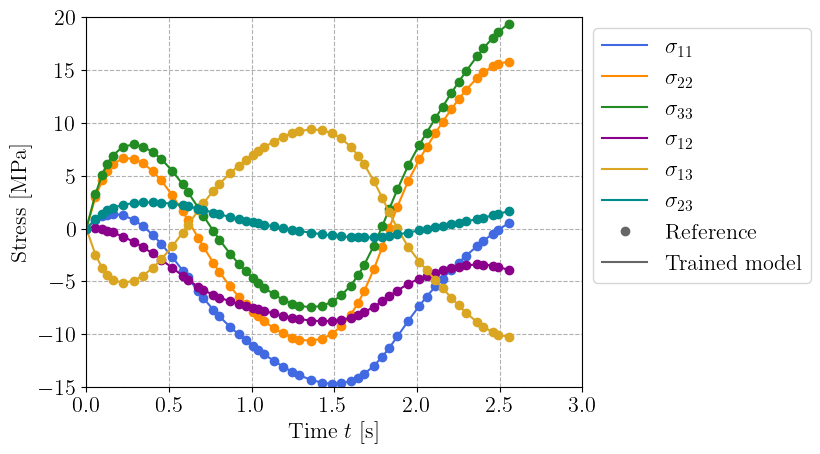

In [10]:
def stress_plot(t, sig_ref, sig_model, held_out, filename):
    fig, ax = plt.subplots()
    for k, (i, j) in enumerate(COMPONENTS):
        ax.plot(
            t,
            sig_ref[:, i, j],
            "o",
            color=COLORS[k],
            mfc="none" if held_out else COLORS[k],
        )
        ax.plot(
            t,
            sig_model[:, i, j],
            color=COLORS[k],
            lw=1.5,
            label=rf"$\sigma_{{{LABELS[k]}}}$",
        )
    ax.plot(
        [], [], "o", color="0.4", mfc="none" if held_out else "0.4", label="Reference"
    )
    ax.plot([], [], color="0.4", lw=1.5, label="Trained model")
    ax.set_xlabel("Time $t$ [s]")
    ax.set_ylabel("Stress [MPa]")
    ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
    for ext in ("pdf", "png"):
        fig.savefig(f"{filename}.{ext}", bbox_inches="tight")
    plt.show()


stress_plot(t_train, sig_train, sig_model_train, False, "training_stress")

The next two figures show the test path with the largest error.

Test path 2, relative error 4.69%


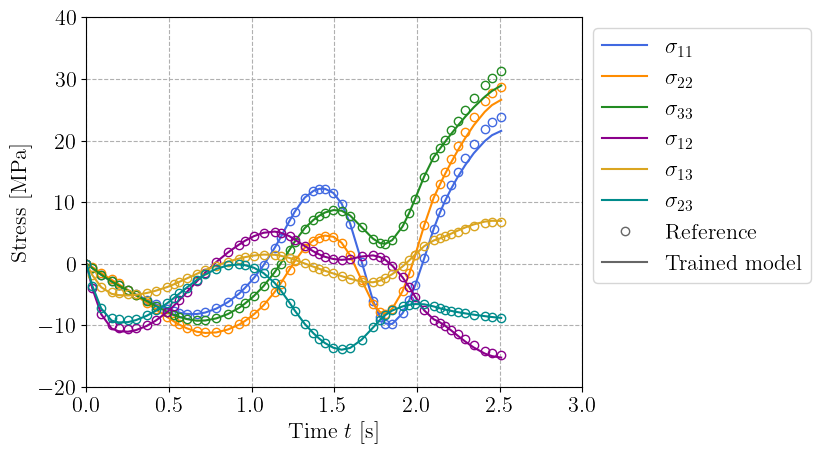

In [11]:
worst = int(np.argmax(test_errors))
t_w, eps_w, sig_w, _, D_ref_w = tests[worst]
print(f"Test path {worst}, relative error {100 * test_errors[worst]:.2f}%")
stress_plot(t_w, sig_w, results[worst][2], True, "test_stress")

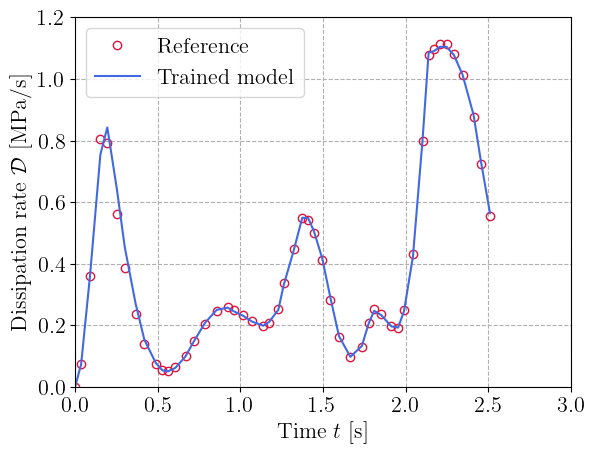

In [12]:
fig, ax = plt.subplots()
ax.plot(t_w, D_ref_w, "o", color="crimson", mfc="none", label="Reference")
ax.plot(t_w, results[worst][3], color="royalblue", lw=1.5, label="Trained model")
ax.set_xlabel("Time $t$ [s]")
ax.set_ylabel(r"Dissipation rate $\mathcal{D}$ [MPa/s]")
ax.set_ylim(bottom=0.0)
ax.legend(loc="upper left")
for ext in ("pdf", "png"):
    fig.savefig(f"dissipation.{ext}", bbox_inches="tight")
plt.show()

## Discussion

The values printed above are reported and discussed in the accompanying paper (section
"Physics-augmented generalized standard material for viscoelasticity").

The physics-augmented model of Rosenkranz et al. is obtained by implementing the free-energy and
dissipation-potential slots of the GSM metamodel with an ICNN and a PICNN of invariants.
Thermodynamic consistency and isotropy follow from the structure of the slots, whatever the
values of the weights: the energy, the stress, the dissipation potential and the thermodynamic
force vanish at the origin, and the potentials are convex, as checked before and after training.
The reference model that generated the data is an instance of the same metamodel, with quadratic
potentials, so that the two models differ only in the implementation of the two slots. The only
additions to the metamodel are the PICNN and the dependence of the dissipation potential on the
state at the beginning of the step.

The model is trained from stress-strain sequences only, without prescribed internal variables.
The "integration" training method of Rosenkranz et al. reduces here to reverse-mode
differentiation through the sequence of implicit incremental updates, the same tool as for the
calibration of the elastoplastic models of the other examples. Some initializations stall at a
much higher training loss and are discarded, as in Rosenkranz et al.

Trained on a single multiaxial path, the model reproduces the stress on unseen multiaxial paths.
Its dissipation rate is non-negative along all test paths and follows that of the reference
model.